Train shape: (10886, 12)
Test shape: (6493, 9)

Train columns:
Index(['datetime', 'season', 'holiday', 'workingday', 'weather', 'temp',
       'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'count'],
      dtype='str')

Test columns:
Index(['datetime', 'season', 'holiday', 'workingday', 'weather', 'temp',
       'atemp', 'humidity', 'windspeed'],
      dtype='str')

Train dtypes:
datetime          str
season          int64
holiday         int64
workingday      int64
weather         int64
temp          float64
atemp         float64
humidity        int64
windspeed     float64
casual          int64
registered      int64
count           int64
dtype: object

Test dtypes:
datetime          str
season          int64
holiday         int64
workingday      int64
weather         int64
temp          float64
atemp         float64
humidity        int64
windspeed     float64
dtype: object

Missing values in train:
datetime      0
season        0
holiday       0
workingday    0
weather     

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
count,10886.000000,10886.000000,10886.000000,10886.000000,10886.00000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000
mean,2.506614,0.028569,0.680875,1.418427,20.23086,23.655084,61.886460,12.799395,36.021955,155.552177,191.574132
std,1.116174,0.166599,0.466159,0.633839,7.79159,8.474601,19.245033,8.164537,49.960477,151.039033,181.144454
min,1.000000,0.000000,0.000000,1.000000,0.82000,0.760000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,0.000000,1.000000,13.94000,16.665000,47.000000,7.001500,4.000000,36.000000,42.000000
50%,3.000000,0.000000,1.000000,1.000000,20.50000,24.240000,62.000000,12.998000,17.000000,118.000000,145.000000
75%,4.000000,0.000000,1.000000,2.000000,26.24000,31.060000,77.000000,16.997900,49.000000,222.000000,284.000000
max,4.000000,1.000000,1.000000,4.000000,41.00000,45.455000,100.000000,56.996900,367.000000,886.000000,977.000000



Test describe:


,season,holiday,workingday,weather,temp,atemp,humidity,windspeed
count,6493.000000,6493.000000,6493.000000,6493.000000,6493.000000,6493.000000,6493.000000,6493.000000
mean,2.493300,0.029108,0.685815,1.436778,20.620607,24.012865,64.125212,12.631157
std,1.091258,0.168123,0.464226,0.648390,8.059583,8.782741,19.293391,8.250151
min,1.000000,0.000000,0.000000,1.000000,0.820000,0.000000,16.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,13.940000,16.665000,49.000000,7.001500
50%,3.000000,0.000000,1.000000,1.000000,21.320000,25.000000,65.000000,11.001400
75%,3.000000,0.000000,1.000000,2.000000,27.060000,31.060000,81.000000,16.997900
max,4.000000,1.000000,1.000000,4.000000,40.180000,50.000000,100.000000,55.998600


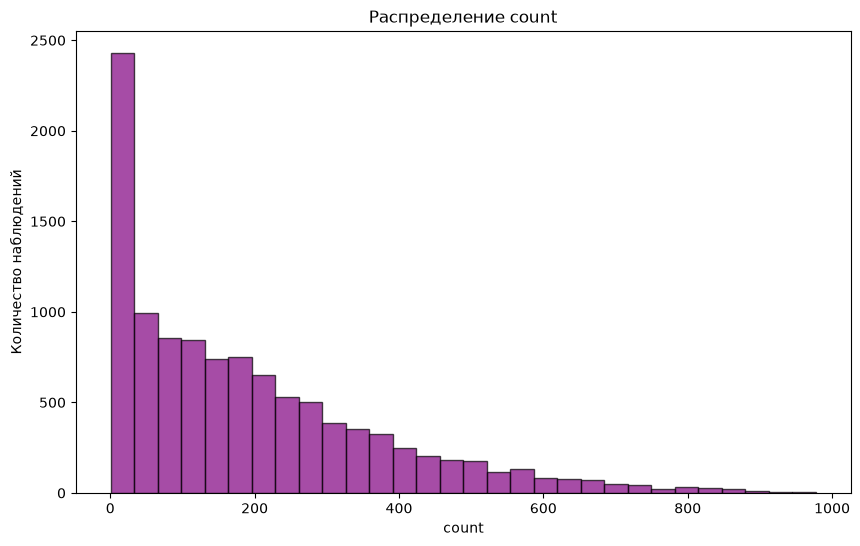

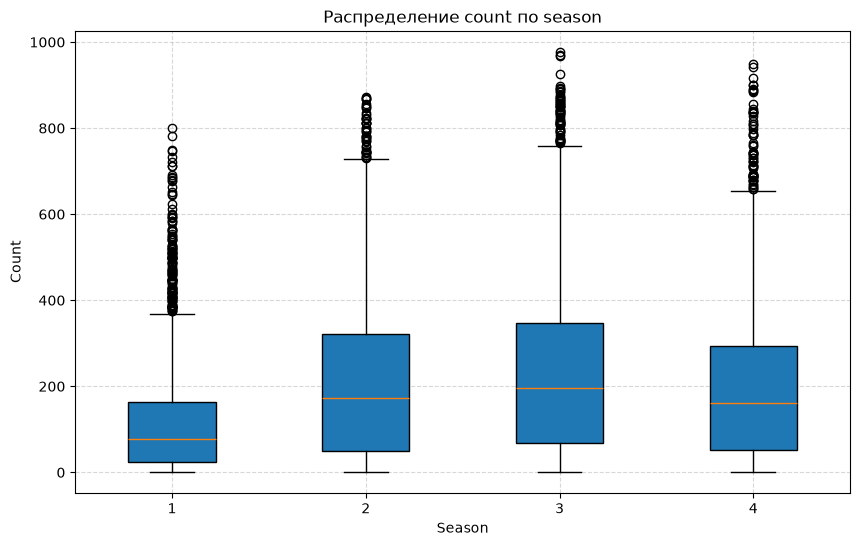

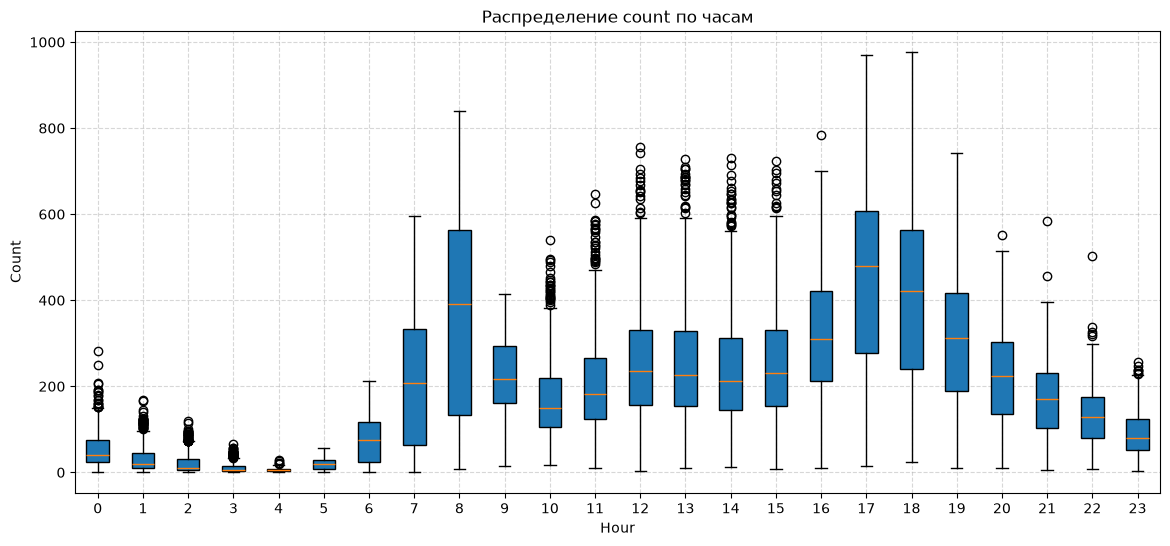

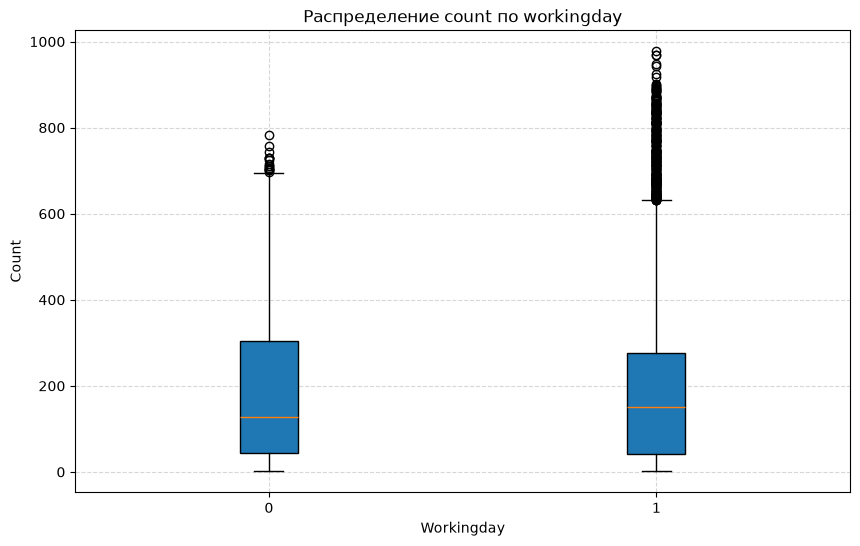

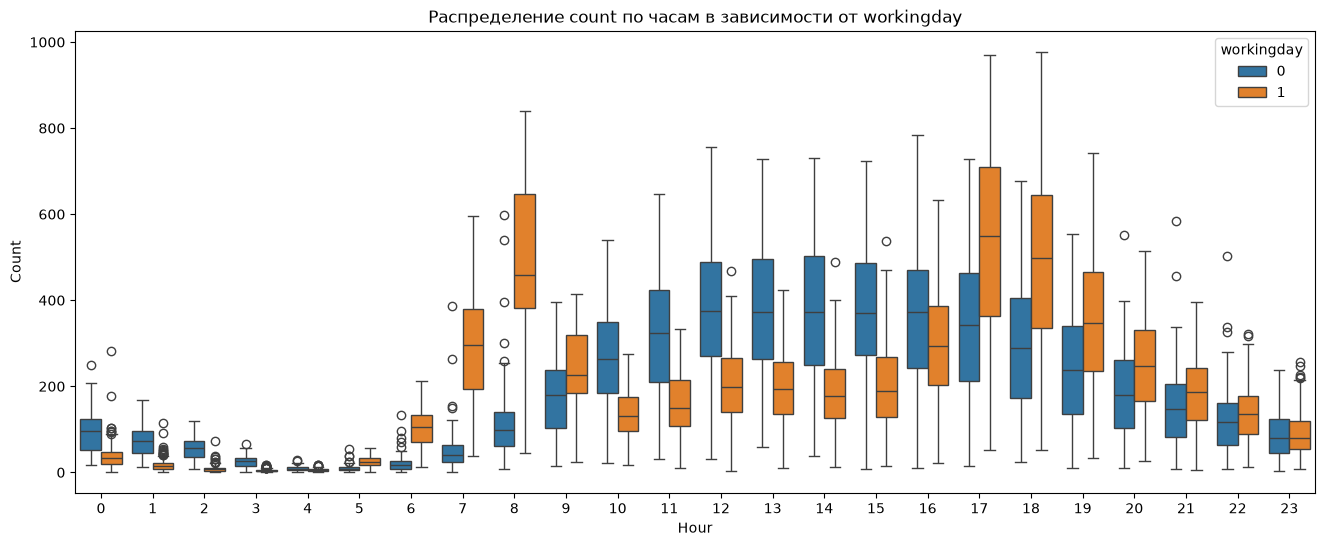

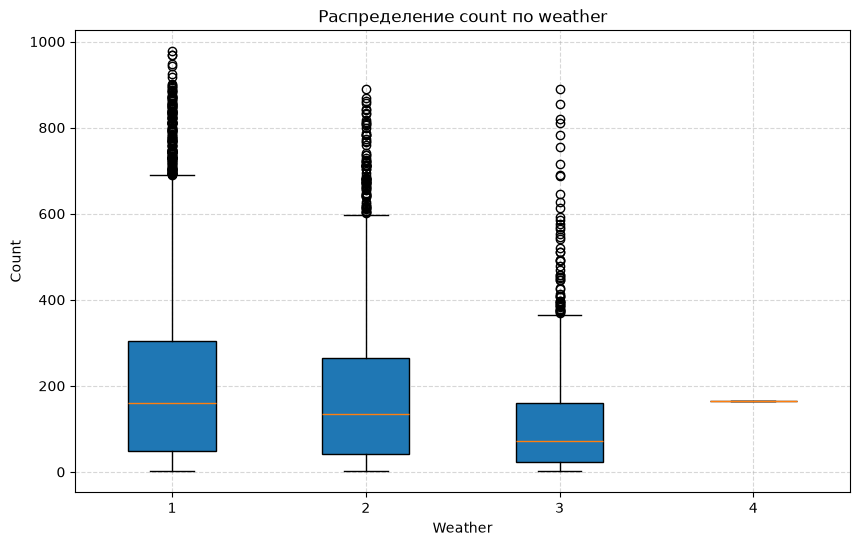

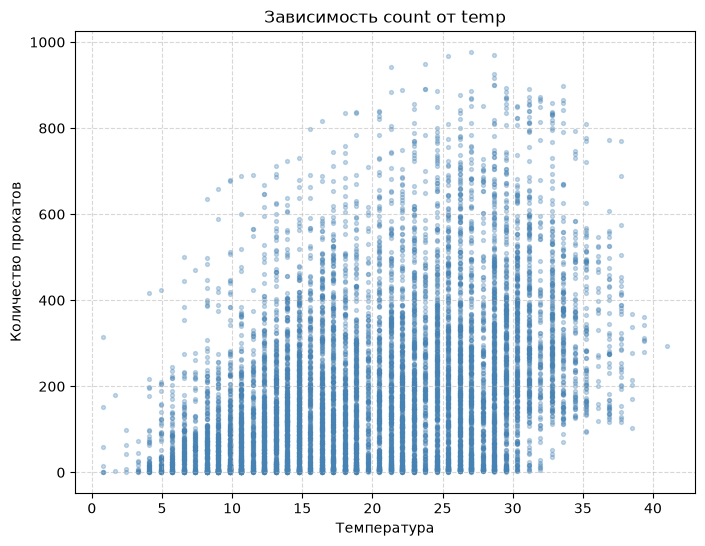

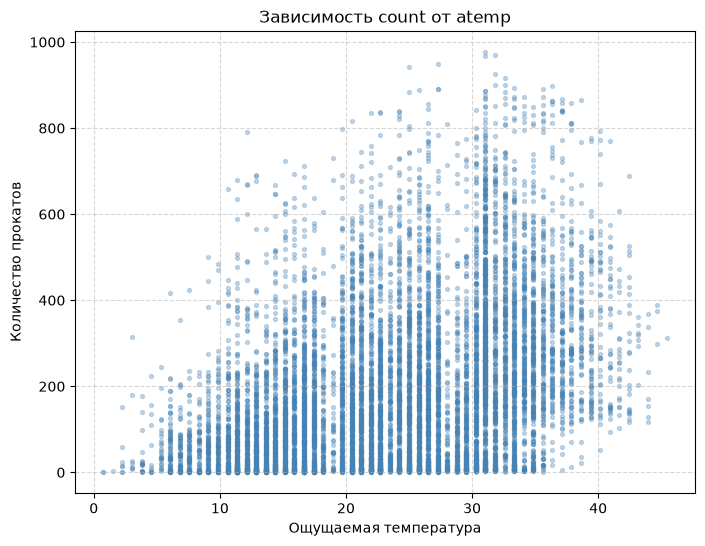

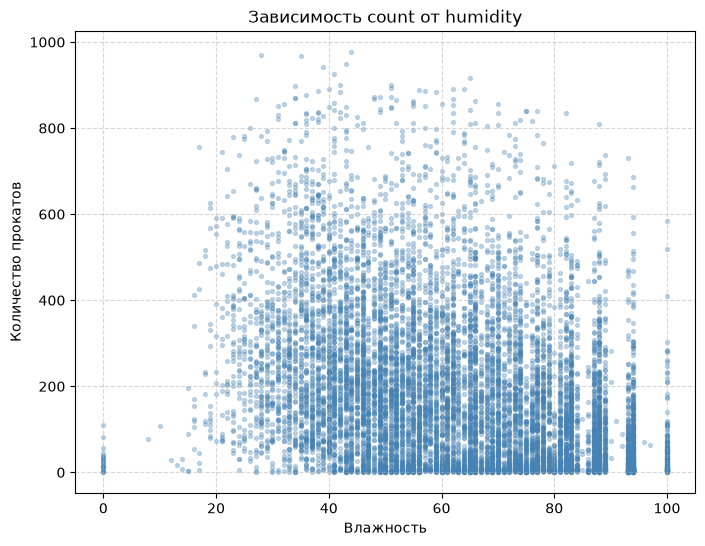

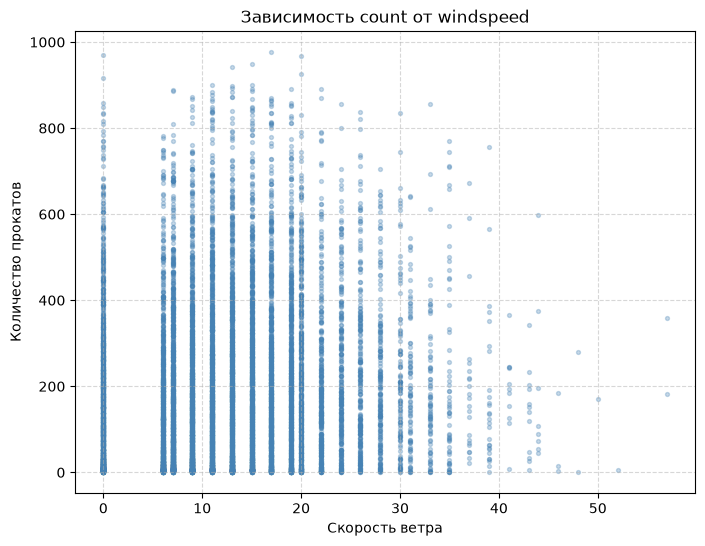

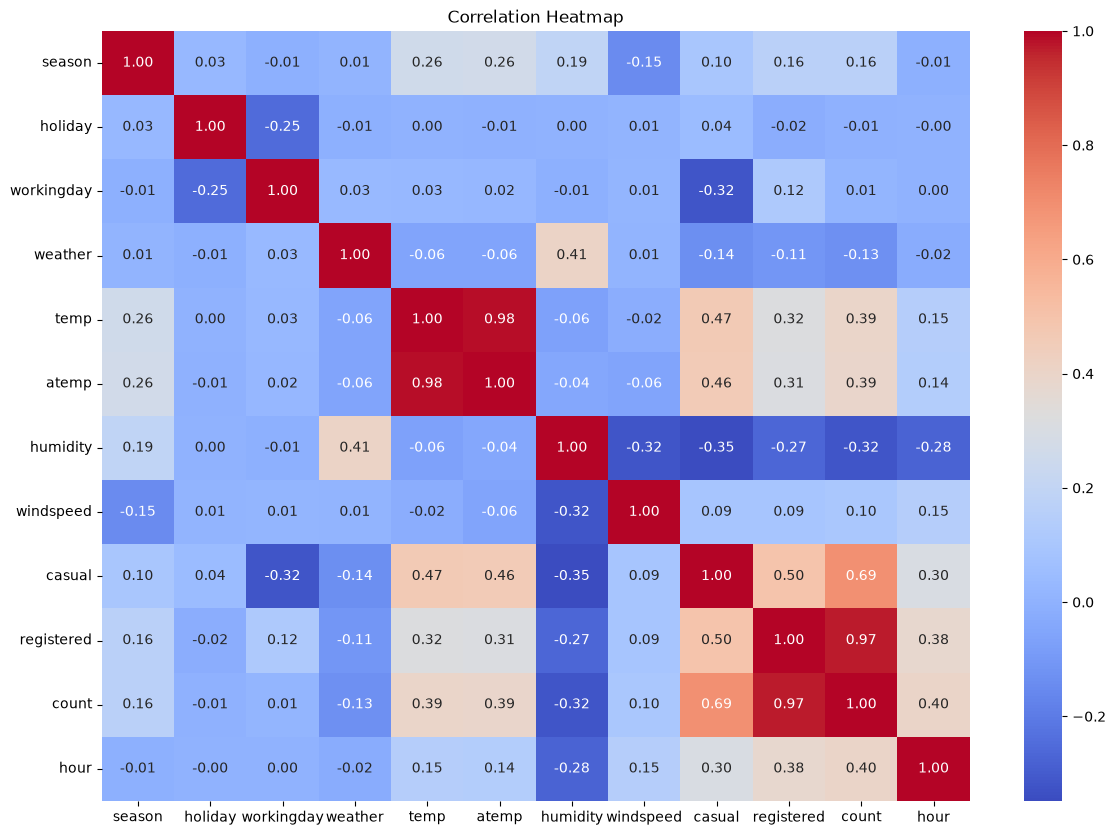

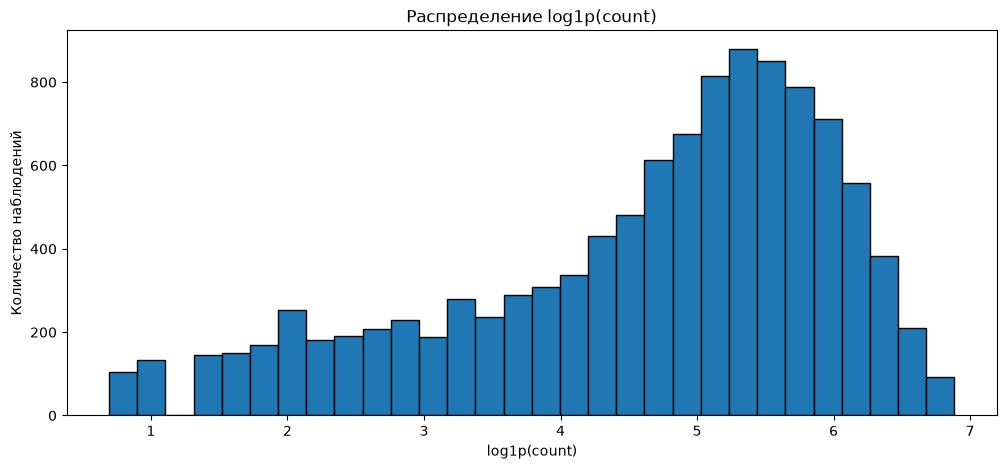

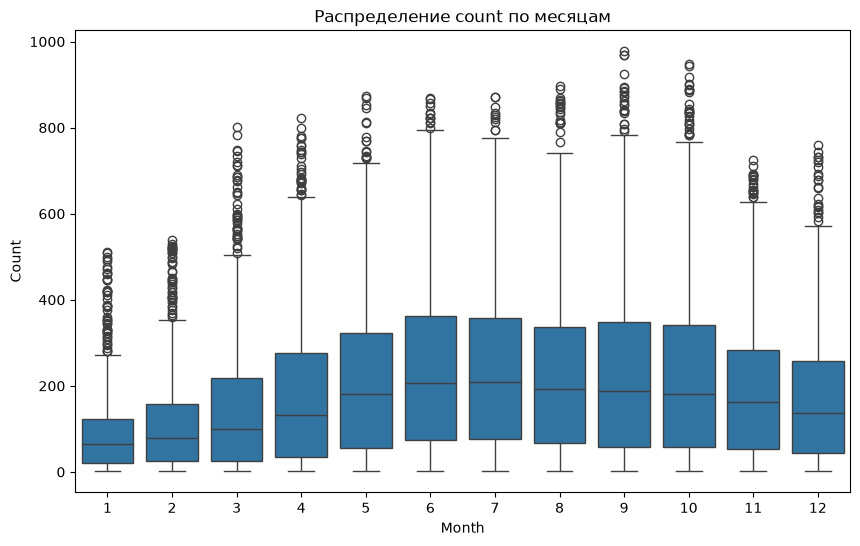

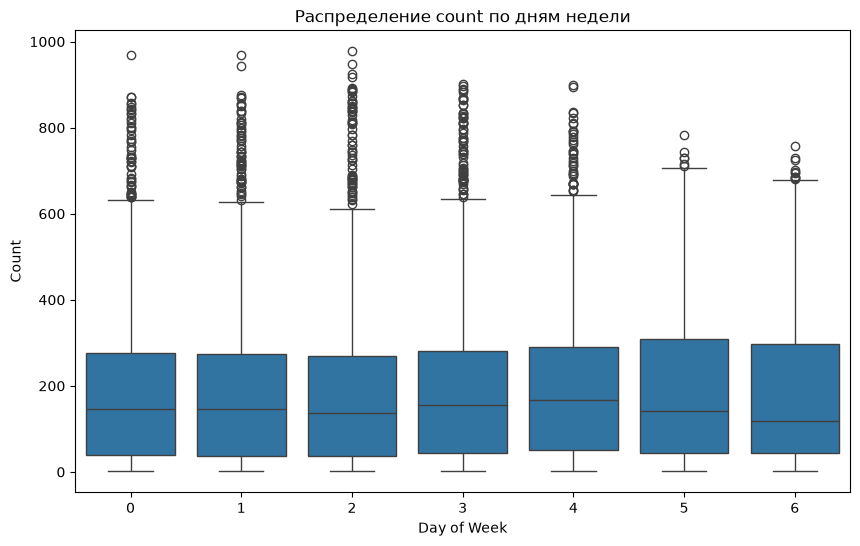

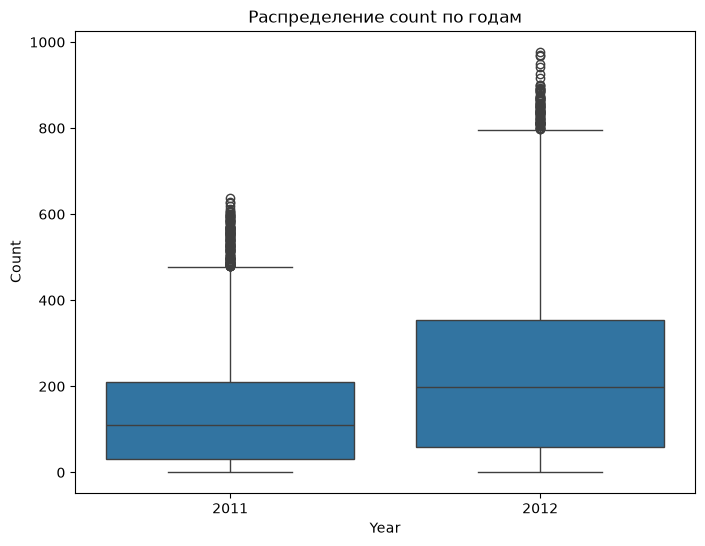

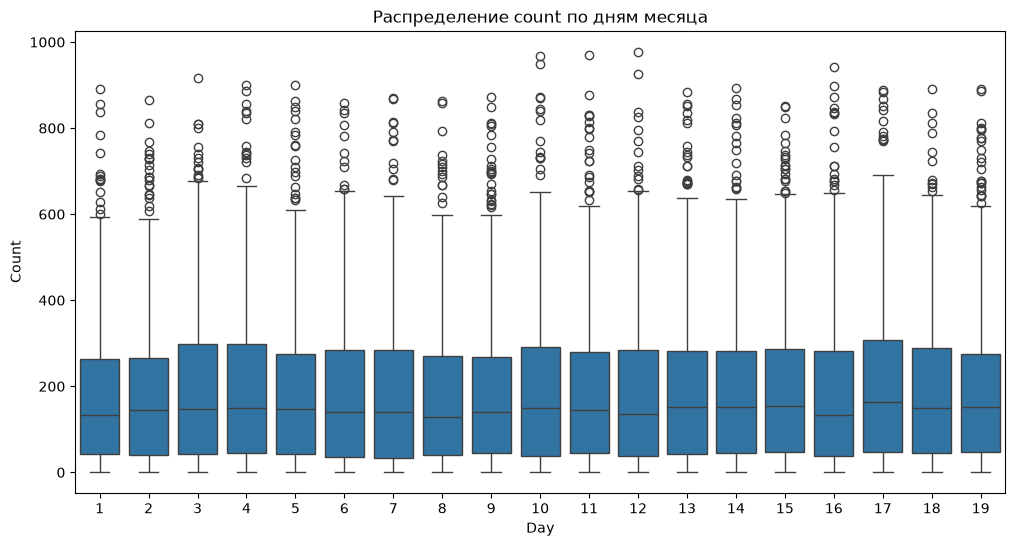

X columns:
Index(['season', 'holiday', 'workingday', 'weather', 'temp', 'atemp',
       'humidity', 'windspeed', 'hour', 'year', 'month', 'day', 'dayofweek'],
      dtype='str')
X_train: (7620, 13)
X_val: (3266, 13)
y_train: (7620,)
y_val: (3266,)
Intersection: 0
Linear Regression RMSLE: 1.0190


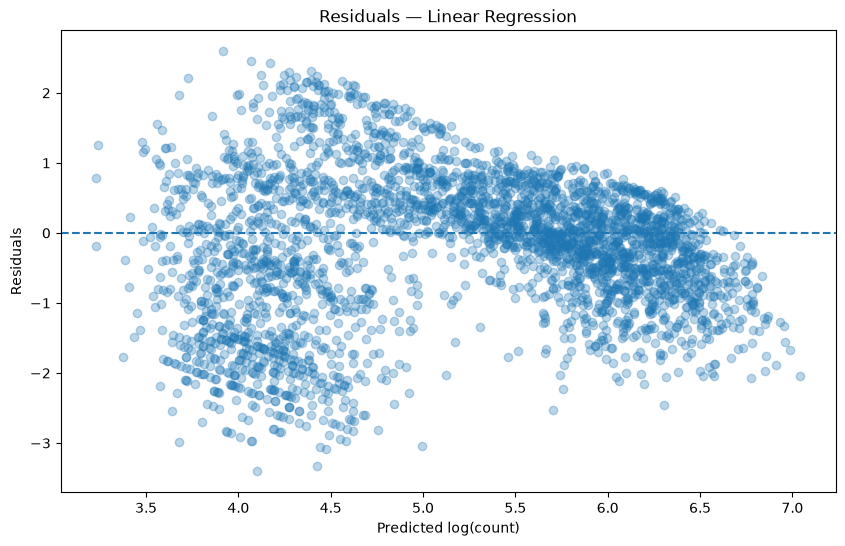

KNN (k=5) RMSLE: 0.9398
k=1: RMSLE=1.1553
k=3: RMSLE=0.9753
k=5: RMSLE=0.9398
k=10: RMSLE=0.9199
k=20: RMSLE=0.9173
k=30: RMSLE=0.9226
k=50: RMSLE=0.9365


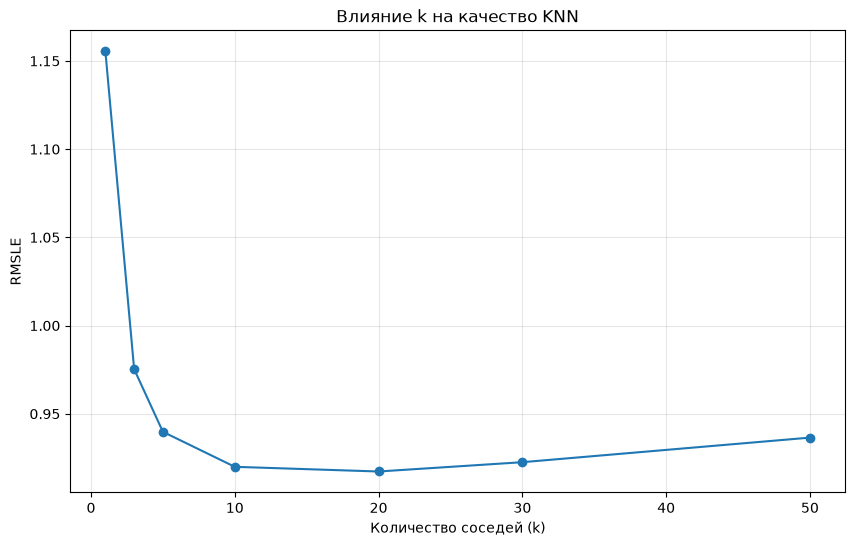

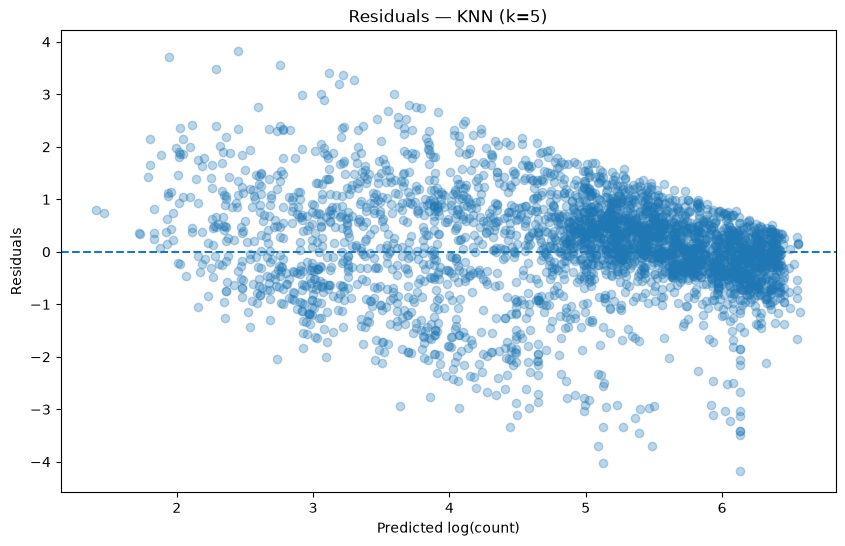

Decision Tree RMSLE: 0.5298
Random Forest RMSLE: 0.3789


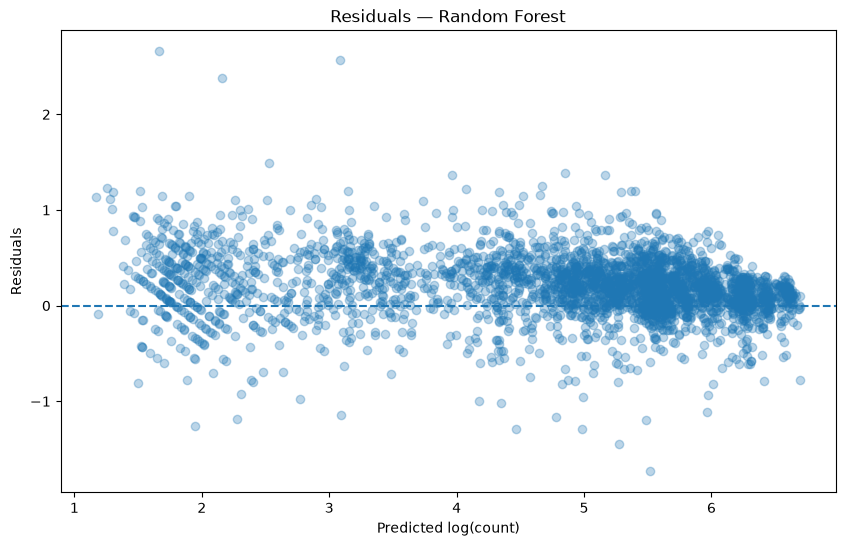

hour          0.760190
atemp         0.039619
temp          0.038850
workingday    0.033199
dayofweek     0.029531
humidity      0.021715
month         0.021091
year          0.016539
weather       0.012556
windspeed     0.009709
day           0.009280
season        0.006386
holiday       0.001334
dtype: float64


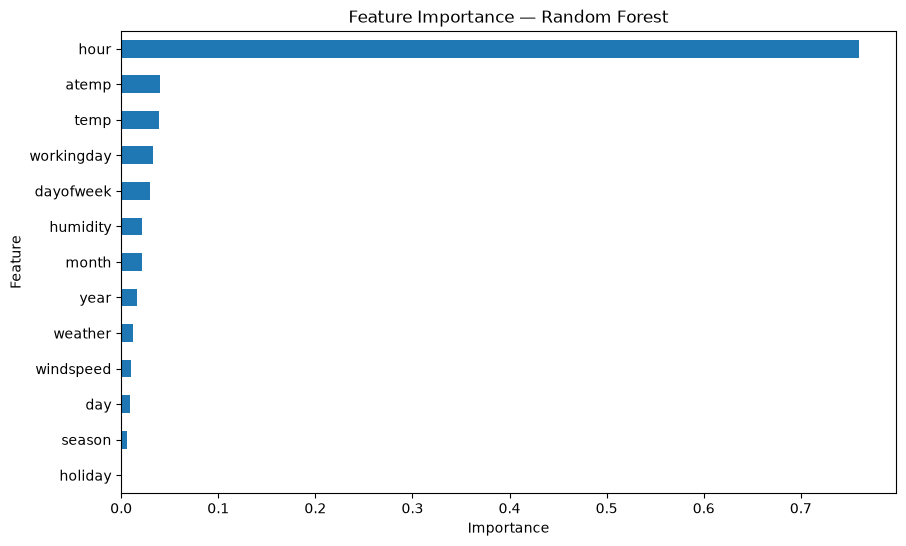

Random Forest + FE RMSLE: 0.3789
Best RF parameters:
{'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': None}
RF CV RMSLE: 0.5639784086376131
RF tuned validation RMSLE: 0.3789
Gradient Boosting RMSLE: 0.3951
Best GB parameters:
{'subsample': 0.9, 'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 0.5, 'max_depth': 5, 'learning_rate': 0.05}
GB CV RMSLE: 0.528600810442414
Tuned Gradient Boosting RMSLE: 0.3200


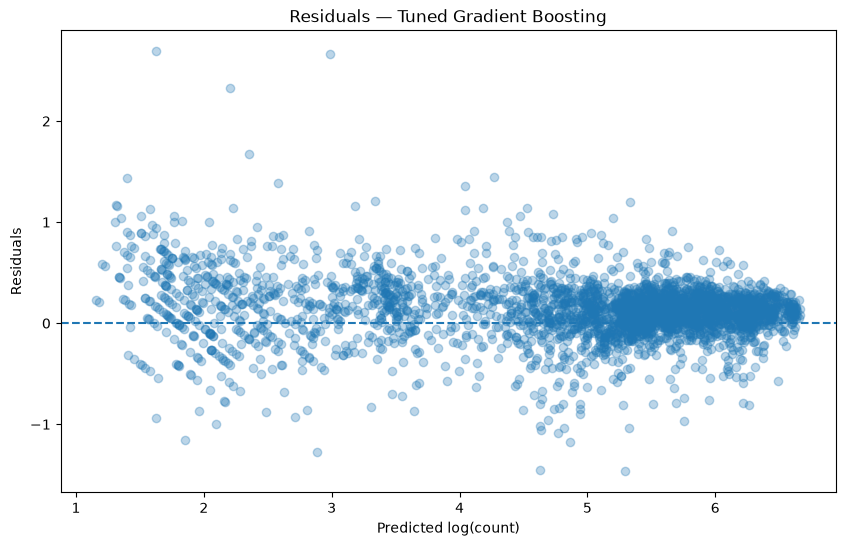

                     Model     RMSLE
0  Tuned Gradient Boosting  0.319952
1            Random Forest  0.378863
2       Random Forest + FE  0.378863
3        Gradient Boosting  0.395052
4            Decision Tree  0.529797
5                KNN (k=5)  0.939777
6        Linear Regression  1.019039


In [655]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# import all libraries and tools I will use

test = pd.read_csv('test.csv')
train = pd.read_csv('train.csv')

# load the data

# Data Audit 
print(test.shape, train.shape)

train.head()
test.head()
train.dtypes
test.dtypes
train.isna().sum()
test.isna().sum()
train.describe()
test.describe()

'''
Data Audit Summary

- the data contains no missing values
- datetime is a temporal feature, other columns are numeric
- season, weather, holiday and workingday are numeric but represent categorical or binary features
- train contains casual and registered features that are absent in test, and count is their sum, 
so using casual and registered to predict count would cause data leakage
- the target count has a wide range from 1 to 977, with the mean above the median,
which suggests a right-skewed target distribution
'''

# build plots to explore relationships between variables
# plot a histogram to analyze the distribution of the target count
plt.hist(train['count'], bins=30, color='purple', edgecolor='black', alpha=0.7)
plt.title('Count distribution')
plt.xlabel('count')
plt.ylabel('Number of observations')
plt.show()

# the count distribution is strongly right-skewed with a long tail
# most observations have a relatively small number of rentals
# while a small portion has very large count values

# group count by each season
data_for_boxplot = [group['count'].values for _, group in train.groupby('season')]

# get labels for the X axis
season_labels = sorted(train['season'].unique())

# build the plot
plt.figure(figsize=(10, 6))
plt.boxplot(data_for_boxplot, tick_labels=season_labels, patch_artist=True)
plt.title('Count boxplot by season')
plt.xlabel('Season')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# the count distribution differs across seasons, so season is potentially a useful feature

# convert datetime to the datetime format for further processing
train['datetime'].dtype
train['datetime'] = pd.to_datetime(train['datetime'])
train['datetime'].dtype

# extract the hour from datetime to test the hypothesis
# about the dependence of bike demand on time of day
train['hour'] = train['datetime'].dt.hour

# group count by each hour
# to compare the demand distribution throughout the day
data_for_boxplot = [
    group['count'].values
    for _, group in train.groupby('hour')
]

# get hours for the X axis labels
hour_labels = sorted(train['hour'].unique())

# build a boxplot of count for each hour
# to visually check demand differences during the day
plt.figure(figsize=(14, 6))
plt.boxplot(data_for_boxplot, tick_labels=hour_labels, patch_artist=True)

plt.title('Count distribution by hour')
plt.xlabel('Hour')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# check the hypothesis using differences in medians and count distributions between hours

# bike demand strongly depends on time of day and has a non-linear shape
# the hour → count relationship is clearly non-linear, so a single numeric hour is not enough
# for a simple linear regression to capture this pattern well

# group count by each workingday
workingday_for_boxplot = [group['count'].values for _, group in train.groupby('workingday')]

# get labels for the X axis
workingday_labels = sorted(train['workingday'].unique())

# build the plot
plt.figure(figsize=(10, 6))
plt.boxplot(workingday_for_boxplot, tick_labels=workingday_labels, patch_artist=True)
plt.title('Count boxplot by workingday')
plt.xlabel('workingday')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# the count distribution differs depending on workingday, so this feature is potentially useful

# I observe that workingday is related to the shape of the count distribution, but the effect is not reduced to a simple rule "working day -> more rentals"

# compare the count distribution for each hour
# separately for working and non-working days
plt.figure(figsize=(16, 6))
sns.boxplot(data=train, x='hour', y='count', hue='workingday')

plt.title('Count distribution by hour depending on workingday')
plt.xlabel('Hour')
plt.ylabel('Count')
plt.show()

'''
The demand profile depends on workingday
On working days there are clear morning and evening peaks
while on weekends demand is more evenly distributed throughout the day
gradually increasing towards midday and decreasing in the evening
'''

# group count by weather
weather_for_boxplot = [group['count'].values for _, group in train.groupby('weather')]

# get labels for the X axis
weather_labels = sorted(train['weather'].unique())

# build the plot
plt.figure(figsize=(10, 6))
plt.boxplot(weather_for_boxplot, tick_labels=weather_labels, patch_artist=True)
plt.title('Count boxplot by weather')
plt.xlabel('Weather')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# as the weather category worsens, the count distribution generally decreases

plt.figure(figsize=(8, 6))
plt.scatter(train['temp'], train['count'], s=8, alpha=0.3, color='steelblue')
plt.title('Scatter plot: temp vs count')
plt.xlabel('Temperature')
plt.ylabel('Number of rentals')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(train['atemp'], train['count'], s=8, alpha=0.3, color='steelblue')
plt.title('Scatter plot: atemp vs count')
plt.xlabel('Temperature')
plt.ylabel('Number of rentals')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# temp and atemp show a very similar relationship with count, so I assume the features are strongly correlated

plt.figure(figsize=(8, 6))
plt.scatter(train['humidity'], train['count'], s=8, alpha=0.3, color='steelblue')
plt.title('Scatter plot: humidity vs count')
plt.xlabel('Humidity')
plt.ylabel('Number of rentals')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# humidity: count grows quickly up to about 40, then gradually decreases up to 100

plt.figure(figsize=(8, 6))
plt.scatter(train['windspeed'], train['count'], s=8, alpha=0.3, color='steelblue')
plt.title('Scatter plot: windspeed vs count')
plt.xlabel('Windspeed')
plt.ylabel('Number of rentals')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# windspeed is relatively stable over some range, after which count decreases
# while in certain ranges there are few or no observations

# build a correlation heatmap to explore relationships between variables
corr = train.corr(numeric_only=True)
plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

# a single correlation matrix is clearly not enough to understand this problem

# transform count logarithmically
# to reduce the influence of the long tail
train['log_count'] = np.log1p(train['count'])

# check how the target distribution changed after log transformation
plt.figure(figsize=(12, 5))
plt.hist(train['log_count'], bins=30, edgecolor='black')
plt.title('Distribution of log1p(count)')
plt.xlabel('log1p(count)')
plt.ylabel('Number of observations')
plt.show()

# after log transformation the count distribution became significantly more symmetric and visually closer to normal
# however a small tail remained

# train a baseline linear regression model
y = np.log1p(train['count'])
x = train.drop(columns=['count', 'casual', 'registered', 'log_count', 'datetime'])
split_index = int(len(x) * 0.7)

x_train = x.iloc[:split_index]
x_val = x.iloc[split_index:]
y_train = y.iloc[:split_index]
y_val = y.iloc[split_index:]

linerreg_model = Pipeline([
    ('model', LinearRegression())
])

# train the model on historical data
linerreg_model.fit(x_train, y_train)

# get predictions on the held-out time split
y_pred = linerreg_model.predict(x_val)
rmse_log_linerreg = np.sqrt(mean_squared_error(y_val, y_pred))
print(rmse_log_linerreg)  # Linear Regression -> RMSLE = 1.0596

# error analysis for the baseline model
residuals = y_val - y_pred

plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(0, linestyle='--')
plt.title('Residuals — Linear Regression')
plt.xlabel('Predicted log(count)')
plt.ylabel('Residuals')
plt.show()

# Linear Regression with RMSLE = 1.06 leaves a clear structure in the residuals
# so it makes sense to try a non-linear model

# build a pipeline
# first scale features to a comparable range
# then find the 5 nearest neighbors
knn_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsRegressor(n_neighbors=5))
])

# train the model on the training part of the data
knn_model.fit(x_train, y_train)

# get predictions
y_pred_knn = knn_model.predict(x_val)
rmse_log_knn = np.sqrt(mean_squared_error(y_val, y_pred_knn))
print(rmse_log_knn)

# KNN (k=5) → 0.7817, which is better than Linear Regression (1.0596)

# check several values of the number of neighbors
# to understand how the choice of k affects KNN quality
k_values = [1, 3, 5, 10, 20, 30, 50]
knn_results = []

for k in k_values:
    # build a pipeline: feature scaling + KNN with the current k
    model_knn = Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsRegressor(n_neighbors=k))
    ])

    # train the model on the time-based train split
    model_knn.fit(x_train, y_train)

    # get predictions on validation
    pred_knn = model_knn.predict(x_val)

    # compute RMSE in log1p space, which corresponds to RMSLE
    rmsle = np.sqrt(mean_squared_error(y_val, pred_knn))

    # save the result of the current experiment
    knn_results.append((k, rmsle))

for k, score in knn_results:
    print(f'k={k}: RMSLE={score:.4f}')

# plot the effect of the number of neighbors on KNN quality
k_values_plot = [k for k, score in knn_results]
scores_plot = [score for k, score in knn_results]

plt.figure(figsize=(10, 6))
plt.plot(k_values_plot, scores_plot, marker='o')
plt.xlabel('Number of neighbors (k)')
plt.ylabel('RMSLE')
plt.title('Effect of k on KNN quality')
plt.grid(True, alpha=0.3)
plt.show()

# among the tested values, k=5 with RMSLE=0.7817 was the best
# at smaller k the model depends more on individual neighbors
# while after k=5 quality gradually degrades due to excessive averaging
# thus, for the current validation split, k=5 was the optimal choice among those tested

# start error analysis for KNN

# compute the residuals of the KNN model
residuals_knn = y_val - y_pred_knn

# plot the KNN residuals
# to check whether there is a systematic structure in the errors
plt.figure(figsize=(10, 6))
plt.scatter(y_pred_knn, residuals_knn, alpha=0.3)
plt.axhline(0, linestyle='--')
plt.title('Residuals — KNN (k=5)')
plt.xlabel('Predicted log(count)')
plt.ylabel('Residuals')
plt.show()

# residual analysis showed that KNN errors are distributed around zero
# but are not completely random and form a clear oval structure
# the model still has noticeable error spread, especially in the middle prediction range
# there is also a significant number of negative residuals
# which indicates overestimation of the target for some observations
# therefore, KNN is better than Linear Regression by RMSLE
# but does not fully capture the patterns in the data

# build a regression tree that will find feature split conditions on its own
tree_model = DecisionTreeRegressor(random_state=42)

# train the tree on the time-based training split
tree_model.fit(x_train, y_train)

# get predictions on validation
y_pred_tree = tree_model.predict(x_val)

# compute RMSE in log1p space, which corresponds to RMSLE
tree_rmsle = np.sqrt(mean_squared_error(y_val, y_pred_tree))
print(tree_rmsle)

'''
Decision Tree showed a significantly better result than Linear Regression (RMSLE 0.5926 vs 1.0596)
which confirms the presence of non-linear relationships and feature interactions in the data
that the linear model could not capture effectively
'''

# build a random forest regressor
rf_model = RandomForestRegressor(random_state=42)

# train the forest on the time-based training split
rf_model.fit(x_train, y_train)

# get predictions on validation
y_pred_rf = rf_model.predict(x_val)

# compute RMSE in log1p space, which corresponds to RMSLE
rf_rmsle = np.sqrt(mean_squared_error(y_val, y_pred_rf))
print(rf_rmsle)

'''
Random Forest showed RMSLE = 0.5024 and outperformed a single Decision Tree (0.5926)
this shows that an ensemble of trees generalizes non-linear relationships and feature interactions better than a single tree
'''

# error analysis for RF to understand how the error pattern changed compared to Decision Tree and KNN
# after that I will decide whether it makes sense to tune the forest

# compute Random Forest residuals
residuals_rf = y_val - y_pred_rf

# plot Random Forest residuals
# to check whether a systematic error structure remains
plt.figure(figsize=(10, 6))
plt.scatter(y_pred_rf, residuals_rf, alpha=0.3)
plt.axhline(0, linestyle='--')
plt.title('Residuals — RF')
plt.xlabel('Predicted log(count)')
plt.ylabel('Residuals')
plt.show()

# error analysis showed that Random Forest residuals do not have a pronounced
# systematic structure typical of Linear Regression
# most errors are concentrated near the zero line, however
# there is a shift toward positive residuals
# meaning the model more often underestimates the target
# Random Forest captures non-linear relationships in the data better
# but systematic errors are not fully eliminated

# get feature importance computed by Random Forest
# based on impurity decrease at splits
feature_importance = pd.Series(rf_model.feature_importances_, index=x_train.columns).sort_values(ascending=False)

# print features from most to least important
print(feature_importance)

# plot feature importance
# to visually compare the contribution of features to Random Forest
plt.figure(figsize=(10, 6))
feature_importance.sort_values().plot(kind='barh')
plt.title('Feature Importance — Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

# feature importance analysis showed that the most important feature
# for RF is hour (importance = 0.766), which is consistent
# with the EDA results and confirms the strong dependence of demand on time of day
# workingday, atemp, temp and humidity also contribute significantly
# at the same time temp and atemp have similar importance and previously showed high
# correlation with each other (0.98), so their duplication should be considered
# in further feature engineering

train_raw = pd.read_csv('train.csv')
train_raw['datetime'] = pd.to_datetime(train_raw['datetime'])
train_raw['dayofweek'] = train_raw['datetime'].dt.dayofweek
train_raw['month'] = train_raw['datetime'].dt.month
train_raw['hour'] = train_raw['datetime'].dt.hour
train_raw['year'] = train_raw['datetime'].dt.year
train_raw['day'] = train_raw['datetime'].dt.day

x['year'] = train['datetime'].dt.year
x['month'] = train['datetime'].dt.month
x['day'] = train['datetime'].dt.day
x['dayofweek'] = train['datetime'].dt.dayofweek

test['datetime'] = pd.to_datetime(test['datetime'])
test['hour'] = test['datetime'].dt.hour
test['year'] = test['datetime'].dt.year
test['month'] = test['datetime'].dt.month
test['day'] = test['datetime'].dt.day
test['dayofweek'] = test['datetime'].dt.dayofweek
test = test.drop(columns=['datetime'])

train['year'] = train['datetime'].dt.year
train['month'] = train['datetime'].dt.month
train['day'] = train['datetime'].dt.day
train['dayofweek'] = train['datetime'].dt.dayofweek
train = train.drop(columns=['log_count', 'registered', 'casual', 'datetime'])

'''
Extract separate temporal features from datetime (year, month, day, dayofweek, hour)
to pass different time-related patterns to the model
that cannot be used directly from the raw datetime
'''

# check whether the count distribution differs by month
sns.boxplot(data=train_raw, x='month', y='count')
plt.title('Count distribution by month')
plt.xlabel('Month')
plt.ylabel('Count')
plt.show()

# analysis of the count distribution by month shows a seasonal pattern
# demand gradually increases in spring, stays high in warm months
# and decreases with the onset of the cold period
# therefore, month can be a useful temporal feature for the model

# check whether the count distribution differs by day of week
sns.boxplot(data=train_raw, x='dayofweek', y='count')
plt.title('Count distribution by day of week')
plt.xlabel('Day of Week')
plt.ylabel('Count')
plt.show()

# check whether the count distribution differs by year
sns.boxplot(data=train_raw, x='year', y='count')
plt.title('Count distribution by year')
plt.xlabel('year')
plt.ylabel('Count')
plt.show()

# check whether the count distribution differs by day
sns.boxplot(data=train_raw, x='day', y='count')
plt.title('Count distribution by day')
plt.xlabel('day')
plt.ylabel('Count')
plt.show()

'''
Extracted year, month, day, dayofweek, hour from datetime
EDA showed clear seasonality by month and demand growth in 2012
The day feature did not show a clear pattern
and the effect of dayofweek turned out to be weak, so I will evaluate its usefulness together with other features in the model
'''

# recreate y, x, x_train, y_train, y_val so that changes after feature engineering are applied
split_index = int(len(x) * 0.7)
y = np.log1p(train['count'])
x_train = x.iloc[:split_index]
x_val = x.iloc[split_index:]
y_train = y.iloc[:split_index]
y_val = y.iloc[split_index:]

# build a random forest regressor after feature engineering
rf_model_fe = RandomForestRegressor(random_state=42)

# train the forest on the time-based training split
rf_model_fe.fit(x_train, y_train)

# get predictions on validation
y_pred_rf_fe = rf_model_fe.predict(x_val)

# compute RMSE in log1p space, which corresponds to RMSLE
rf_rmsle_fe = np.sqrt(mean_squared_error(y_val, y_pred_rf_fe))
print(rf_rmsle_fe)

# tuning Random Forest parameters should improve RMSLE compared to the current value through a better ensemble complexity and structure

# set a time-based split for cross-validation
# so that during tuning the model always trains on the past
# and is evaluated on the following time segment
tscv = TimeSeriesSplit(n_splits=5)

# define hyperparameter ranges
# to find the optimal RF complexity
param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 10, 15, 20, 25, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [0.5, 0.7, 1.0]
}

# build a random search over parameter combinations
# use MSE in log1p space as the metric
# which matches the RMSLE logic
rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=20,
    scoring='neg_mean_squared_error',
    cv=tscv,
    random_state=42,
    n_jobs=-1
)

# tune parameters only on the training part
# without using the final validation split
rf_search.fit(x_train, y_train)
print(rf_search.best_params_)
print(np.sqrt(-rf_search.best_score_))

# evaluate the best model found during tuning
# on the fully held-out validation split
y_pred_rf_tuned = rf_search.best_estimator_.predict(x_val)

# compute RMSLE in log1p space
rf_tuned_rmsle = np.sqrt(mean_squared_error(y_val, y_pred_rf_tuned))
print(rf_tuned_rmsle)

'''
Hyperparameter tuning in the given range did not improve Random Forest
The best configuration matched the default model parameters
so further Random Forest complexity at this stage is not worthwhile
'''

'''
Sequential building of trees where each next tree tries to correct the errors of the previous ones
should give a more accurate prediction than an independent RF ensemble
'''

# build a baseline Gradient Boosting (GB)
model_gb = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3)

# train GB on the time-based training split
model_gb.fit(x_train, y_train)

# get predictions on validation
y_pred_gb = model_gb.predict(x_val)

# compute RMSE in log1p space, which corresponds to RMSLE
rmsle_gb = np.sqrt(mean_squared_error(y_val, y_pred_gb))
print(rmsle_gb)

# can Gradient Boosting tuning beat Random Forest
# if I balance the number of trees, learning rate and complexity of each tree

# set a time-based split for cross-validation
# so that during tuning the model always trains on the past
# and is evaluated on the following time segment
tscv_gb = TimeSeriesSplit(n_splits=5)

# define hyperparameter ranges
# to find the optimal model complexity
param_dist_gb = {
    'n_estimators': [100, 200, 300, 500],
    'learning_rate': [0.01, 0.05, 0.1],  
    'max_depth': [3, 5, 7, 10],          
    'min_samples_split': [2, 5, 10, 20], 
    'min_samples_leaf': [1, 2, 4, 8],    
    'max_features': ['sqrt', 'log2', 0.5, 0.7, 1.0],  
    'subsample': [0.8, 0.9, 1.0] 
}

# build a random search over parameter combinations
# use MSE in log1p space as the metric
# which matches the RMSLE logic
rf_search_gb = RandomizedSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_distributions=param_dist_gb,
    n_iter=20,
    scoring='neg_mean_squared_error',
    cv=tscv_gb,
    random_state=42,
    n_jobs=-1
)

# tune parameters only on the training part
# without using the final validation split
rf_search_gb.fit(x_train, y_train)
print(rf_search_gb.best_params_)
print(np.sqrt(-rf_search_gb.best_score_))

# evaluate the best model found during tuning
# on the fully held-out validation split
y_pred_gb_tuned = rf_search_gb.best_estimator_.predict(x_val)

# compute RMSLE in log1p space
gb_tuned_rmsle = np.sqrt(mean_squared_error(y_val, y_pred_gb_tuned))
print(gb_tuned_rmsle)

# check whether the residual structure disappeared compared to Random Forest and where the model still makes mistakes
# error analysis for tuned Gradient Boosting

residuals_gb = y_val - y_pred_gb_tuned

plt.figure(figsize=(10, 6))
plt.scatter(y_pred_gb_tuned, residuals_gb, alpha=0.3)
plt.axhline(0, linestyle='--')
plt.title('Residuals — Tuned Gradient Boosting')
plt.xlabel('Predicted log(count)')
plt.ylabel('Residuals')
plt.show()

# error analysis showed that tuned Gradient Boosting has no pronounced
# geometric residual structure typical of Linear Regression
# most errors are concentrated near the zero line
# the largest residual spread is observed at smaller and medium predictions
# at large prediction values errors become more compact
# however individual large errors remain, so the model does not fully
# eliminate errors across all target ranges

In [657]:
# final part

import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor

# 1 load the initial data

train_final = pd.read_csv('/kaggle/input/competitions/bike-sharing-demand/train.csv')
test_final = pd.read_csv('/kaggle/input/competitions/bike-sharing-demand/test.csv')

# 2 save the original datetime from test for the submission file

test_datetime = test_final['datetime'].copy()

# 3 convert datetime to the proper format

train_final['datetime'] = pd.to_datetime(train_final['datetime'])
test_final['datetime'] = pd.to_datetime(test_final['datetime'])

# 4 perform feature engineering
# create identical features for train and test to ensure consistency

for df in [train_final, test_final]:
    df['year'] = df['datetime'].dt.year
    df['month'] = df['datetime'].dt.month
    df['dayofweek'] = df['datetime'].dt.dayofweek
    df['hour'] = df['datetime'].dt.hour

# 5 create the target with logarithmic transformation

y_final = np.log1p(train_final['count'])

# 6 create X
# drop the target leakage features and datetime

X_final = train_final.drop(columns=['count', 'casual', 'registered', 'datetime'])
X_test_final = test_final.drop(columns=['datetime'])

# 7 verify that train and test have the same features and no missing values

assert list(X_final.columns) == list(X_test_final.columns)
assert X_final.isna().sum().sum() == 0
assert X_test_final.isna().sum().sum() == 0

# 8 set the best parameters found during tuning

best_gb_params = {
    'n_estimators': 300,
    'learning_rate': 0.05,
    'max_depth': 5,
    'min_samples_split': 10,
    'min_samples_leaf': 4,
    'max_features': 0.5,
    'subsample': 0.9
}

# 9 create the final model

final_gb = GradientBoostingRegressor(
    **best_gb_params,
    random_state=42
)

# 10 train the model on the entire train dataset

final_gb.fit(X_final, y_final)

# 11 get predictions for test
# the model predicts log1p(count)

test_pred_log = final_gb.predict(X_test_final)

# 12 revert predictions to the original count scale
# exclude negative values just in case

test_pred = np.expm1(test_pred_log)
test_pred = np.maximum(test_pred, 0)

# 13 create the submission dataframe

submission = pd.DataFrame({
    'datetime': test_datetime,
    'count': test_pred
})


# 14 perform a final data check before saving

assert len(submission) == len(test_final)
assert submission['count'].isna().sum() == 0
assert np.isfinite(submission['count']).all()
assert (submission['count'] >= 0).all()

print('Submission size:', submission.shape)
print('\nFirst rows:')
print(submission.head())
print('\nNumber of NaNs:')
print(submission.isna().sum())
print('\nMinimum count:', submission['count'].min())
print('Maximum count:', submission['count'].max())

# 15 save the file

submission.to_csv('submission.csv', index=False)
print('\nsubmission.csv successfully saved')

'''
the best model turned out to be the tuned Gradient Boosting with the temporal features year, 
month, dayofweek and hour
on the local validation split I got RMSLE ≈ 0.320, and on Kaggle — 0.39975
removing the day feature, which did not show a clear pattern in EDA and could create a distribution 
gap between train and test,
slightly improved the final Kaggle score
'''

Размер submission: (6493, 2)

Первые строки:
              datetime     count
0  2011-01-20 00:00:00  9.617107
1  2011-01-20 01:00:00  4.594331
2  2011-01-20 02:00:00  3.039720
3  2011-01-20 03:00:00  2.047515
4  2011-01-20 04:00:00  2.036588

Количество NaN:
datetime    0
count       0
dtype: int64

Минимальный count: 1.1200753326107589
Максимальный count: 858.0672250755829

submission.csv успешно сохранён
